# Pneumonia detection from chest X-rays

In my machine learning summative I worked on early warning for sepsis in ICU patients, using hourly vital signs and lab values. That data was tabular. For this MLOps project the data had to be images or sound, so I went one step back in the same story. Pneumonia is the most common infection that turns into sepsis, and a chest X-ray is usually how it gets confirmed. If a model can flag pneumonia on the X-ray early, the patient gets treated before the sepsis stage.

**Dataset.** Chest X-ray images from Kermany et al. (2018), published on Mendeley Data under CC BY 4.0 (doi:10.17632/rscbjbr9sj.2). The images are front-view chest X-rays of children aged one to five from Guangzhou Women and Children's Medical Center, labelled NORMAL or PNEUMONIA by doctors. There are 5,856 images in total.

**Task.** Binary classification, NORMAL vs PNEUMONIA.

This notebook covers data acquisition, preprocessing, four training experiments, evaluation on the held-out test set, the prediction function used by the API, and a retraining run. The same functions live in `src/` and are used by the deployed app, so what I test here is what runs in production.

In [1]:
import os, sys, json, time
from pathlib import Path
if Path.cwd().name == "notebook":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

from src.config import TRAIN_DIR, TEST_DIR, NEW_BATCH_DIR, CLASS_NAMES, SEED, IMG_SIZE
from src import data_acquisition, insights
from src.preprocessing import list_images, patient_split, make_dataset, class_weights
from src.model import (build_baseline_cnn, build_transfer_model, unfreeze_top, compile_model,
                       callbacks, predict_proba, evaluate, best_threshold, save_model, load_model)

tf.keras.utils.set_random_seed(SEED)
pd.set_option("display.precision", 3)
Path("figures").mkdir(exist_ok=True)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Data acquisition

`src/data_acquisition.py` downloads the zip from Mendeley (1.2 GB), checks the SHA-256 so I know the file is not corrupted, extracts it and writes a 224x224 grayscale copy of every image into `data/train` and `data/test`. The original images are big (often 2000 pixels wide) and decoding them every epoch was slow, so resizing once saves a lot of time.

Two choices I made here:

The official split has a `val` folder with only 16 images. That is too small to choose anything with, so I put those 16 back into train and make my own validation set later.

I also moved about 120 images (whole patients) out of train into `data/new_batch`. I never train on them in this notebook. They stand in for new X-rays that arrive after the model is deployed, and I use them to test retraining in the app.

In [2]:
data_acquisition.main()

train_df = list_images(TRAIN_DIR)
test_df = list_images(TEST_DIR)
new_df = list_images(NEW_BATCH_DIR)
summary = pd.DataFrame({
    "train": train_df.label.value_counts(),
    "test": test_df.label.value_counts(),
    "new_batch": new_df.label.value_counts(),
})
summary.loc["total"] = summary.sum()
summary

zip already downloaded
already extracted
train/NORMAL: 1349 original images
train/PNEUMONIA: 3883 original images
test/NORMAL: 234 original images
test/PNEUMONIA: 390 original images
new_batch already exists


,train,test,new_batch
label,,,
PNEUMONIA,3822,390,61
NORMAL,1289,234,60
total,5111,624,121


## 2. Looking at the data

Before training anything I wanted to know what separates the two classes, and whether there is anything in the images that a model could use as a shortcut. `src/insights.py` reads every original image and records its size, overall brightness, contrast, and the brightness of the centre of the image (roughly where the lungs are). The same numbers feed the Insights page of the app.

In [3]:
raw = insights.raw_image_table()
insights.mean_images()
info = insights.build(raw)
raw.groupby("label")[["width", "height", "brightness", "contrast", "centre_brightness"]].median().round(1)

,width,height,brightness,contrast,centre_brightness
label,,,,,
NORMAL,1654.0,1323.0,122.4,61.5,138.9
PNEUMONIA,1160.0,776.0,122.9,54.8,152.6


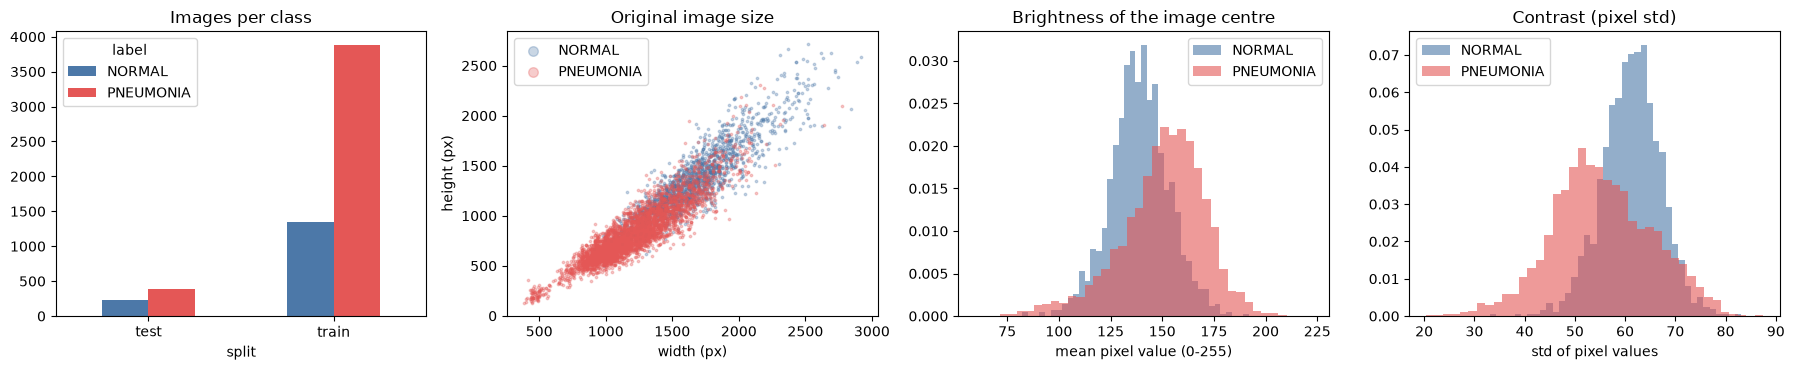

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
counts = raw.groupby(["split", "label"]).size().unstack()
counts.plot.bar(ax=axes[0], color=["#4C78A8", "#E45756"], rot=0)
axes[0].set_title("Images per class")
for label, color in zip(CLASS_NAMES, ["#4C78A8", "#E45756"]):
    sub = raw[raw.label == label]
    axes[1].scatter(sub.width, sub.height, s=3, alpha=0.3, color=color, label=label)
    axes[2].hist(sub.centre_brightness, bins=40, alpha=0.6, density=True, color=color, label=label)
    axes[3].hist(sub.contrast, bins=40, alpha=0.6, density=True, color=color, label=label)
axes[1].set(title="Original image size", xlabel="width (px)", ylabel="height (px)")
axes[2].set(title="Brightness of the image centre", xlabel="mean pixel value (0-255)")
axes[3].set(title="Contrast (pixel std)", xlabel="std of pixel values")
for ax in axes[1:]:
    ax.legend(markerscale=4)
plt.tight_layout()
plt.savefig("figures/eda_features.png", dpi=120)
plt.show()

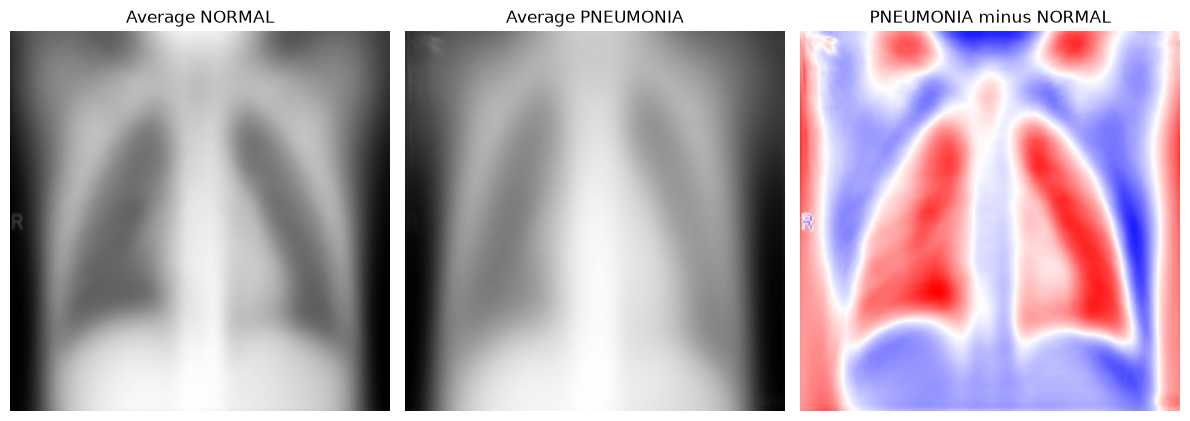

pneumonia subtypes: {'bacterial': 2780, 'normal': 1583, 'viral': 1493}
median centre brightness by subtype: {'bacterial': 151.2, 'normal': 138.9, 'viral': 155.2}


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, name, title in zip(axes, ["mean_normal", "mean_pneumonia", "mean_difference"],
                           ["Average NORMAL", "Average PNEUMONIA", "PNEUMONIA minus NORMAL"]):
    ax.imshow(Image.open(f"data/insights/{name}.png"), cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig("figures/mean_images.png", dpi=120)
plt.show()
print("pneumonia subtypes:", info["subtype_counts"])
print("median centre brightness by subtype:", info["brightness_by_subtype"])

**What I take from this**

The classes are not balanced. About 74% of the training images are pneumonia, while the test set is 62.5% pneumonia. So a model that always answers "pneumonia" already scores 74% accuracy on train, and I can't judge anything by accuracy alone.

The brightness of the centre is the feature that actually makes medical sense. Pneumonia images are brighter in the middle (median 152 against 139), and viral cases are the brightest of all. On an X-ray air is black and fluid is white, so lungs full of fluid turn lighter. The whole-image brightness is the same for both classes, which tells me it is not just a difference in exposure. Contrast tells the same story from the other side: pneumonia images are hazier, with a lower pixel standard deviation (55 vs 61).

The image size surprised me. Normal images are a lot bigger (1654 x 1323 median) than pneumonia images (1160 x 776), and the shape is different too. That cannot be caused by the disease. It most likely comes from how the images were collected or cropped. Resizing everything to 224 x 224 hides the size, but the pneumonia images get squeezed differently, so the model could still pick up on it.

In the average images I also noticed a small "R" marker on the left of the average normal X-ray. The normal images have it in almost the same place every time. I kept these two things in mind when I looked at the errors later.

## 3. Preprocessing

The steps, in the order they happen:

1. **Grayscale and resize to 224x224.** Done once in data acquisition (`src/preprocessing.py`, `to_xray_array`). It also applies the EXIF rotation, which matters later for phone photos uploaded to the app.
2. **Grayscale to 3 channels.** MobileNetV2 was trained on colour images and expects 3 channels, so I repeat the gray channel. The scaling to the range -1 to 1 is a `Rescaling` layer inside the model, so the API can send raw 0 to 255 pixels and there is no way to forget it.
3. **Validation split by patient.** Some children have several X-rays. If I split images at random, the same child can end up in train and validation and the validation score looks better than it is. The patient id is in the file name (`person1000_bacteria_2931` and `IM-0115-0001`), so I split on that, 85/15.
4. **Augmentation, training only.** Small rotations (about 10 degrees), zoom, shifts and contrast changes. I left out horizontal flips on purpose. A flipped chest X-ray puts the heart on the wrong side, which never happens in real data.
5. **Class weights.** About 74% of the training images are pneumonia, so the loss gives each normal image more weight.
6. **tf.data pipeline** with parallel decoding, caching of the validation and test sets, and prefetching.

In [6]:
train_split, val_split = patient_split(train_df, val_frac=0.15)
print(f"train {len(train_split)} images, validation {len(val_split)} images")
print("patients in both:", len(set(train_split.patient) & set(val_split.patient)))
print("pneumonia share  train %.3f  val %.3f  test %.3f" % (train_split.y.mean(), val_split.y.mean(), test_df.y.mean()))

weights = class_weights(train_split.y)
print("class weights:", {CLASS_NAMES[k]: round(v, 2) for k, v in weights.items()})

BATCH = 32
train_ds = make_dataset(train_split.path, train_split.y, BATCH, training=True, augment=False)
train_ds_aug = make_dataset(train_split.path, train_split.y, BATCH, training=True, augment=True)
val_ds = make_dataset(val_split.path, val_split.y, BATCH)
test_ds = make_dataset(test_df.path, test_df.y, BATCH)

train 4374 images, validation 737 images
patients in both: 0
pneumonia share  train 0.746  val 0.756  test 0.625
class weights: {'NORMAL': np.float64(1.97), 'PNEUMONIA': np.float64(0.67)}


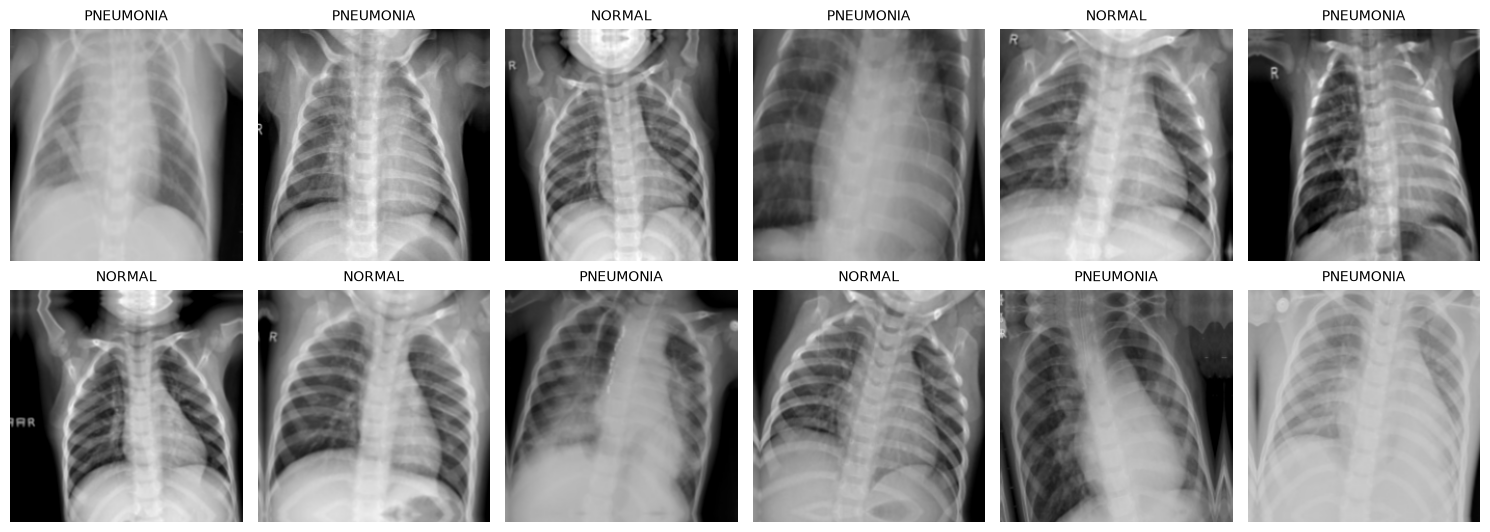

In [7]:
# what the model actually sees after augmentation
x, y = next(iter(train_ds_aug))
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(x[i].numpy().astype("uint8"))
    ax.set_title(CLASS_NAMES[int(y[i])], fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Experiments

I ran four experiments, each one changing one main thing from the one before. Every run uses Adam, binary cross-entropy, early stopping on validation loss (best weights restored) and ReduceLROnPlateau. TensorBoard logs go to `logs/fit/`.

| Run | Model | What changes |
|---|---|---|
| E1 | Small CNN from scratch (4 conv blocks) | baseline, with augmentation and class weights |
| E2 | MobileNetV2 (ImageNet), base frozen | transfer learning, no augmentation, no class weights |
| E3 | MobileNetV2, base frozen | + augmentation, class weights, dropout 0.4, L2 1e-4 |
| E4 | E3, then last 40 layers unfrozen | fine-tuning with a 100x smaller learning rate (1e-5) |

I picked MobileNetV2 because the model has to run in a small cloud container and answer many requests at once. It has about 2.3 million parameters, which is small next to ResNet50 (about 25 million).

In [8]:
results, histories = {}, {}

def run(name, model, train_data, epochs, lr, class_weight=None, patience=4):
    compile_model(model, lr)
    t = time.time()
    h = model.fit(train_data, validation_data=val_ds, epochs=epochs, class_weight=class_weight,
                  callbacks=callbacks(log_dir=f"logs/fit/{name}", patience=patience), verbose=2)
    minutes = (time.time() - t) / 60
    histories[name] = h.history
    val_prob = predict_proba(model, val_ds)
    test_prob = predict_proba(model, test_ds)
    results[name] = {"model": model, "val_prob": val_prob, "test_prob": test_prob, "minutes": minutes,
                     "epochs": len(h.history["loss"]),
                     "val": evaluate(val_split.y, val_prob), "test": evaluate(test_df.y, test_prob)}
    t = results[name]["test"]
    print(f"{name}: {len(h.history['loss'])} epochs, {minutes:.1f} min | test acc {t['accuracy']:.3f} "
          f"F1 {t['f1']:.3f} recall {t['recall']:.3f} specificity {t['specificity']:.3f} AUC {t['roc_auc']:.3f}")
    return model

### E1: CNN from scratch

In [9]:
e1 = run("E1_cnn_scratch", build_baseline_cnn(), train_ds_aug, epochs=15, lr=1e-3, class_weight=weights)

Epoch 1/15


/Users/kalisabelyse/Documents/projects/ALU-Projects/pneumonia-xray-mlops/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


137/137 - 41s - 296ms/step - accuracy: 0.8608 - auc: 0.9352 - loss: 0.3208 - precision: 0.9621 - recall: 0.8469 - val_accuracy: 0.7558 - val_auc: 0.5000 - val_loss: 1.7016 - val_precision: 0.7558 - val_recall: 1.0000 - learning_rate: 0.0010


Epoch 2/15


137/137 - 65s - 473ms/step - accuracy: 0.8919 - auc: 0.9585 - loss: 0.2568 - precision: 0.9729 - recall: 0.8796 - val_accuracy: 0.7558 - val_auc: 0.5157 - val_loss: 1.4585 - val_precision: 0.7558 - val_recall: 1.0000 - learning_rate: 0.0010


Epoch 3/15


... (22 outputs left out)

137/137 - 202s - 1s/step - accuracy: 0.9666 - auc: 0.9955 - loss: 0.0896 - precision: 0.9906 - recall: 0.9645 - val_accuracy: 0.9389 - val_auc: 0.9917 - val_loss: 0.1575 - val_precision: 0.9923 - val_recall: 0.9264 - learning_rate: 9.0000e-05


Epoch 15/15


137/137 - 119s - 869ms/step - accuracy: 0.9659 - auc: 0.9954 - loss: 0.0874 - precision: 0.9927 - recall: 0.9614 - val_accuracy: 0.9512 - val_auc: 0.9939 - val_loss: 0.1410 - val_precision: 0.9943 - val_recall: 0.9408 - learning_rate: 9.0000e-05


E1_cnn_scratch: 15 epochs, 13.7 min | test acc 0.804 F1 0.864 recall 0.992 specificity 0.491 AUC 0.934


### E2: MobileNetV2, frozen base, nothing else

In [10]:
e2 = run("E2_mobilenet_frozen", build_transfer_model(dropout=0.2, l2=0.0), train_ds, epochs=10, lr=1e-3)

Epoch 1/10


/Users/kalisabelyse/Documents/projects/ALU-Projects/pneumonia-xray-mlops/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


137/137 - 28s - 205ms/step - accuracy: 0.9316 - auc: 0.9780 - loss: 0.1616 - precision: 0.9499 - recall: 0.9590 - val_accuracy: 0.9579 - val_auc: 0.9944 - val_loss: 0.0910 - val_precision: 0.9598 - val_recall: 0.9856 - learning_rate: 0.0010


Epoch 2/10


137/137 - 24s - 176ms/step - accuracy: 0.9643 - auc: 0.9906 - loss: 0.0996 - precision: 0.9764 - recall: 0.9758 - val_accuracy: 0.9715 - val_auc: 0.9944 - val_loss: 0.0815 - val_precision: 0.9855 - val_recall: 0.9767 - learning_rate: 0.0010


Epoch 3/10


... (12 outputs left out)

137/137 - 15s - 111ms/step - accuracy: 0.9849 - auc: 0.9985 - loss: 0.0450 - precision: 0.9890 - recall: 0.9908 - val_accuracy: 0.9701 - val_auc: 0.9947 - val_loss: 0.0863 - val_precision: 0.9872 - val_recall: 0.9731 - learning_rate: 9.0000e-05


Epoch 10/10


137/137 - 15s - 111ms/step - accuracy: 0.9835 - auc: 0.9981 - loss: 0.0437 - precision: 0.9887 - recall: 0.9893 - val_accuracy: 0.9701 - val_auc: 0.9949 - val_loss: 0.0842 - val_precision: 0.9872 - val_recall: 0.9731 - learning_rate: 9.0000e-05


E2_mobilenet_frozen: 10 epochs, 3.1 min | test acc 0.804 F1 0.864 recall 0.997 specificity 0.483 AUC 0.958


### E3: MobileNetV2 with augmentation, class weights and regularisation

In [11]:
e3 = run("E3_mobilenet_regularised", build_transfer_model(dropout=0.4, l2=1e-4), train_ds_aug,
         epochs=15, lr=1e-3, class_weight=weights)

Epoch 1/15


/Users/kalisabelyse/Documents/projects/ALU-Projects/pneumonia-xray-mlops/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


137/137 - 19s - 139ms/step - accuracy: 0.8964 - auc: 0.9645 - loss: 0.2634 - precision: 0.9640 - recall: 0.8946 - val_accuracy: 0.9525 - val_auc: 0.9925 - val_loss: 0.1408 - val_precision: 0.9888 - val_recall: 0.9479 - learning_rate: 0.0010


Epoch 2/15


137/137 - 20s - 146ms/step - accuracy: 0.9305 - auc: 0.9821 - loss: 0.1895 - precision: 0.9780 - recall: 0.9277 - val_accuracy: 0.9566 - val_auc: 0.9918 - val_loss: 0.1304 - val_precision: 0.9613 - val_recall: 0.9820 - learning_rate: 0.0010


Epoch 3/15


... (6 outputs left out)

137/137 - 19s - 135ms/step - accuracy: 0.9408 - auc: 0.9870 - loss: 0.1635 - precision: 0.9802 - recall: 0.9397 - val_accuracy: 0.9566 - val_auc: 0.9937 - val_loss: 0.1440 - val_precision: 0.9981 - val_recall: 0.9443 - learning_rate: 3.0000e-04


Epoch 7/15


137/137 - 21s - 150ms/step - accuracy: 0.9474 - auc: 0.9899 - loss: 0.1451 - precision: 0.9844 - recall: 0.9446 - val_accuracy: 0.9607 - val_auc: 0.9938 - val_loss: 0.1187 - val_precision: 0.9889 - val_recall: 0.9587 - learning_rate: 3.0000e-04


E3_mobilenet_regularised: 7 epochs, 2.2 min | test acc 0.819 F1 0.873 recall 0.995 specificity 0.526 AUC 0.958


### E4: fine-tuning the top of MobileNetV2

I start from the E3 weights and let the last 40 layers of MobileNetV2 train. The learning rate drops from 1e-3 to 1e-5, otherwise the big gradients from the new head would destroy the pretrained filters in the first few steps. BatchNorm layers stay frozen for the same reason (with batches of 32 their statistics would jump around).

In [12]:
e4 = unfreeze_top(e3, n_layers=40)
print("trainable weights:", sum(int(np.prod(w.shape)) for w in e4.trainable_weights))
e4 = run("E4_mobilenet_finetuned", e4, train_ds_aug, epochs=10, lr=1e-5, class_weight=weights)

trainable weights: 1827457
Epoch 1/10


/Users/kalisabelyse/Documents/projects/ALU-Projects/pneumonia-xray-mlops/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


137/137 - 31s - 224ms/step - accuracy: 0.9419 - auc: 0.9856 - loss: 0.1695 - precision: 0.9830 - recall: 0.9384 - val_accuracy: 0.9661 - val_auc: 0.9950 - val_loss: 0.0996 - val_precision: 0.9836 - val_recall: 0.9713 - learning_rate: 1.0000e-05


Epoch 2/10


137/137 - 28s - 202ms/step - accuracy: 0.9511 - auc: 0.9896 - loss: 0.1492 - precision: 0.9860 - recall: 0.9479 - val_accuracy: 0.9607 - val_auc: 0.9953 - val_loss: 0.1042 - val_precision: 0.9835 - val_recall: 0.9641 - learning_rate: 1.0000e-05


Epoch 3/10


... (12 outputs left out)

137/137 - 23s - 171ms/step - accuracy: 0.9714 - auc: 0.9957 - loss: 0.0949 - precision: 0.9919 - recall: 0.9697 - val_accuracy: 0.9742 - val_auc: 0.9963 - val_loss: 0.0872 - val_precision: 0.9786 - val_recall: 0.9874 - learning_rate: 3.0000e-06


Epoch 10/10


137/137 - 22s - 160ms/step - accuracy: 0.9744 - auc: 0.9968 - loss: 0.0879 - precision: 0.9937 - recall: 0.9718 - val_accuracy: 0.9756 - val_auc: 0.9966 - val_loss: 0.0874 - val_precision: 0.9909 - val_recall: 0.9767 - learning_rate: 3.0000e-06


E4_mobilenet_finetuned: 10 epochs, 4.2 min | test acc 0.825 F1 0.877 recall 1.000 specificity 0.534 AUC 0.969


## 5. Comparing the experiments

All numbers below use a 0.5 threshold. Test is the official test set (624 images from different patients), which was not used for any choice.

In [13]:
rows = []
for name, r in results.items():
    for split in ("val", "test"):
        m = r[split]
        rows.append({"run": name, "split": split, "epochs": r["epochs"], "minutes": round(r["minutes"], 1),
                     **{k: m[k] for k in ("loss", "accuracy", "precision", "recall", "specificity", "f1", "roc_auc")}})
table = pd.DataFrame(rows)
Path("results").mkdir(exist_ok=True)
table.to_csv("results/experiments.csv", index=False)
table[table.split == "test"].drop(columns="split").set_index("run")

,epochs,minutes,loss,accuracy,precision,recall,specificity,f1,roc_auc
run,,,,,,,,,
E1_cnn_scratch,15,13.7,0.595,0.804,0.765,0.992,0.491,0.864,0.934
E2_mobilenet_frozen,10,3.1,0.709,0.804,0.763,0.997,0.483,0.864,0.958
E3_mobilenet_regularised,7,2.2,0.538,0.819,0.778,0.995,0.526,0.873,0.958
E4_mobilenet_finetuned,10,4.2,0.638,0.825,0.782,1.000,0.534,0.877,0.969


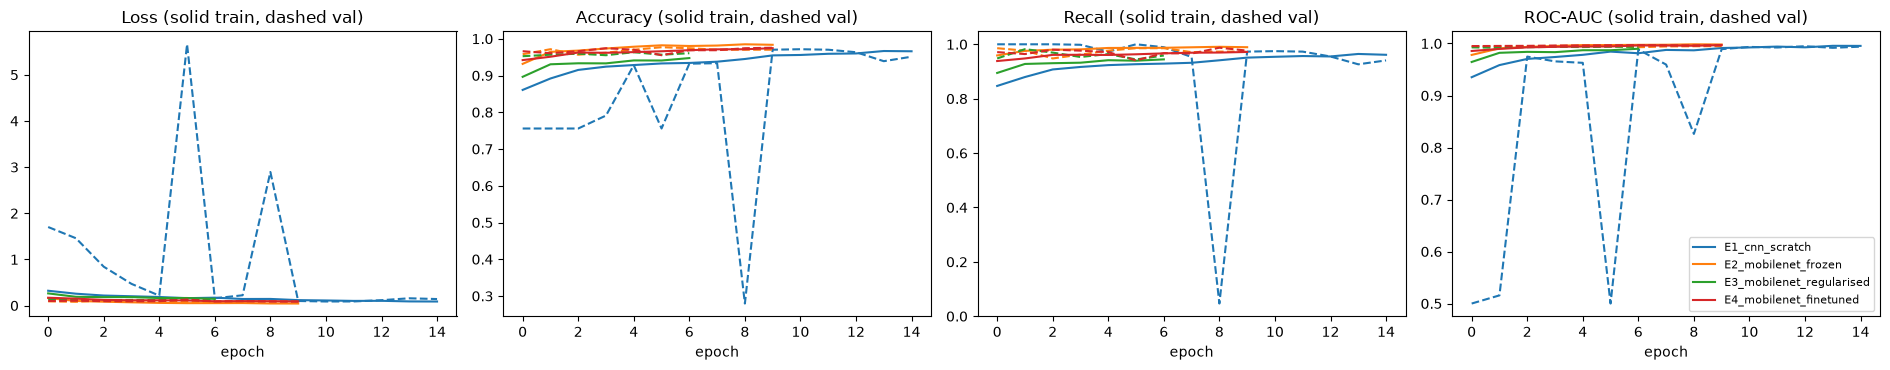

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))
for name, h in histories.items():
    line, = axes[0].plot(h["loss"], label=f"{name} train")
    axes[0].plot(h["val_loss"], "--", color=line.get_color())
    axes[1].plot(h["accuracy"], color=line.get_color())
    axes[1].plot(h["val_accuracy"], "--", color=line.get_color())
    axes[2].plot(h["recall"], color=line.get_color())
    axes[2].plot(h["val_recall"], "--", color=line.get_color())
    axes[3].plot(h["auc"], color=line.get_color(), label=name)
    axes[3].plot(h["val_auc"], "--", color=line.get_color())
for ax, t in zip(axes, ["Loss", "Accuracy", "Recall", "ROC-AUC"]):
    ax.set(title=f"{t} (solid train, dashed val)", xlabel="epoch")
axes[3].legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/learning_curves.png", dpi=120)
plt.show()

**What happened in the experiments**

The first thing I noticed was the gap between validation and test. Every model reached around 96 to 97% accuracy on validation but only 80 to 83% on test. Validation comes from the same folder as training, so it shares whatever made those images look the way they do. The test set seems to come from a slightly different mix of images, and the models were not ready for it.

E1, the CNN from scratch, was the most unstable. Look at the dashed blue line in the loss plot: validation loss jumps to 5.7 at epoch 6 and 2.9 at epoch 9, and validation recall falls to 0.05 at one point. The training loss goes down smoothly the whole time, so the problem is not learning, it is the BatchNorm statistics being shaky in a network that starts from random weights. It settled once ReduceLROnPlateau lowered the learning rate. It also took 13.7 minutes, more than the other three runs together.

E2 used MobileNetV2 with nothing extra. It trained in 3 minutes and its test ROC-AUC went from 0.934 to 0.958, so the ImageNet filters helped a lot even though X-rays look nothing like ImageNet photos. But the training accuracy (98.4%) ended clearly above validation, which is the start of overfitting, and test specificity was the worst of all four (0.483).

E3 added augmentation, class weights, more dropout and L2. Training accuracy dropped to about 94 to 95% and stayed below validation, so the regularisation did its job. Early stopping ended it after 7 epochs. Test specificity went up to 0.526 and F1 to 0.873.

E4 fine-tuned the top 40 layers of MobileNetV2 with a very small learning rate and was the best on every test number: F1 0.877, ROC-AUC 0.969, PR-AUC 0.979. The train and validation curves stay close, so it is not overfitting the training folder. Its weakness is the same as all the others, which is what the next sections are about.

Bias and variance: E1 has high variance (its validation scores jump around between epochs). E2 starts to overfit. E3 and E4 have small train/validation gaps, so on data like the training data they are fine. The error that is left on the test set is not variance, it is a shift between the training data and the test data.

## 6. Choosing the threshold

With 0.5 as the cut-off the model calls too many normal X-rays pneumonia on the test set (see the specificity column). I can't choose the threshold on the test set, that would be cheating, so I choose the one that gives the best F1 on the validation set and then check it once on the test set. The threshold goes into `models/metadata.json` and the API reads it from there.

In [15]:
final_name = "E4_mobilenet_finetuned"
final = results[final_name]
threshold = best_threshold(val_split.y, final["val_prob"])
val_metrics = evaluate(val_split.y, final["val_prob"], threshold)
test_metrics = evaluate(test_df.y, final["test_prob"], threshold)
print("chosen threshold:", round(threshold, 2))
pd.DataFrame({"test @0.5": final["test"], f"test @{threshold:.2f}": test_metrics}).drop(["confusion_matrix", "n"]).T

chosen threshold: 0.49


,threshold,loss,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc
test @0.5,0.5,0.638,0.825,0.782,1.0,0.534,0.877,0.969,0.979
test @0.49,0.49,0.638,0.825,0.782,1.0,0.534,0.877,0.969,0.979


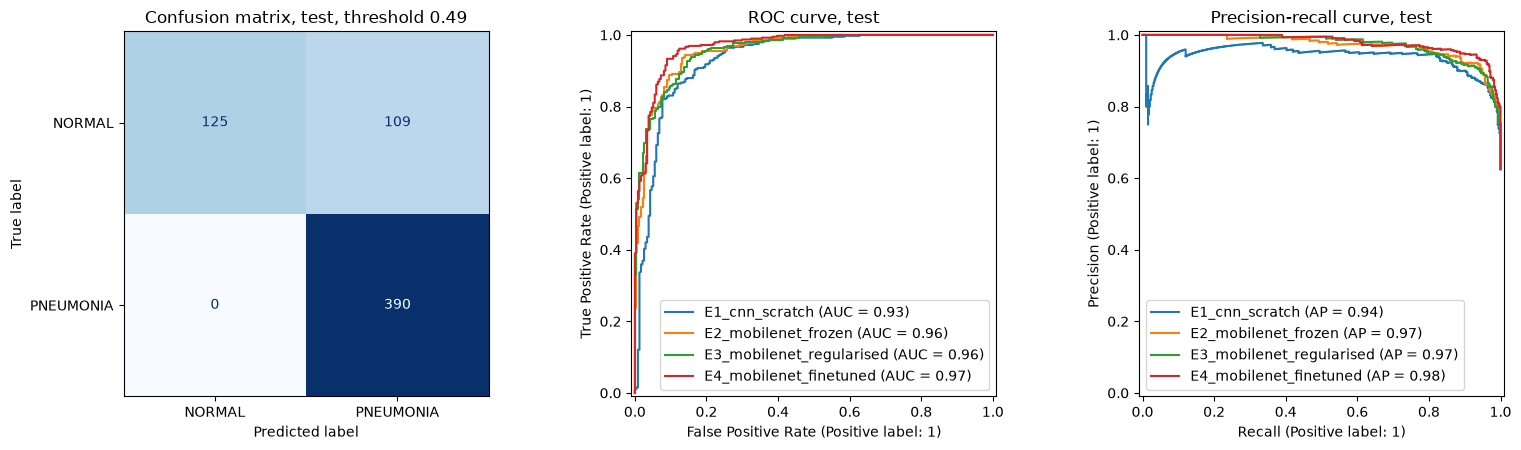

              precision    recall  f1-score   support

      NORMAL      1.000     0.534     0.696       234
   PNEUMONIA      0.782     1.000     0.877       390

    accuracy                          0.825       624
   macro avg      0.891     0.767     0.787       624
weighted avg      0.863     0.825     0.810       624



In [16]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay, classification_report

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
ConfusionMatrixDisplay(np.array(test_metrics["confusion_matrix"]), display_labels=CLASS_NAMES).plot(ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title(f"Confusion matrix, test, threshold {threshold:.2f}")
for name, r in results.items():
    RocCurveDisplay.from_predictions(test_df.y, r["test_prob"], name=name, ax=axes[1])
    PrecisionRecallDisplay.from_predictions(test_df.y, r["test_prob"], name=name, ax=axes[2])
axes[1].set_title("ROC curve, test")
axes[2].set_title("Precision-recall curve, test")
plt.tight_layout()
plt.savefig("figures/confusion_roc_pr.png", dpi=120)
plt.show()

print(classification_report(test_df.y, (final["test_prob"] >= threshold).astype(int), target_names=CLASS_NAMES, digits=3))

## 7. Error analysis

These are the test images the final model got wrong with the most confidence.

109 wrong out of 624: {'NORMAL': 109}


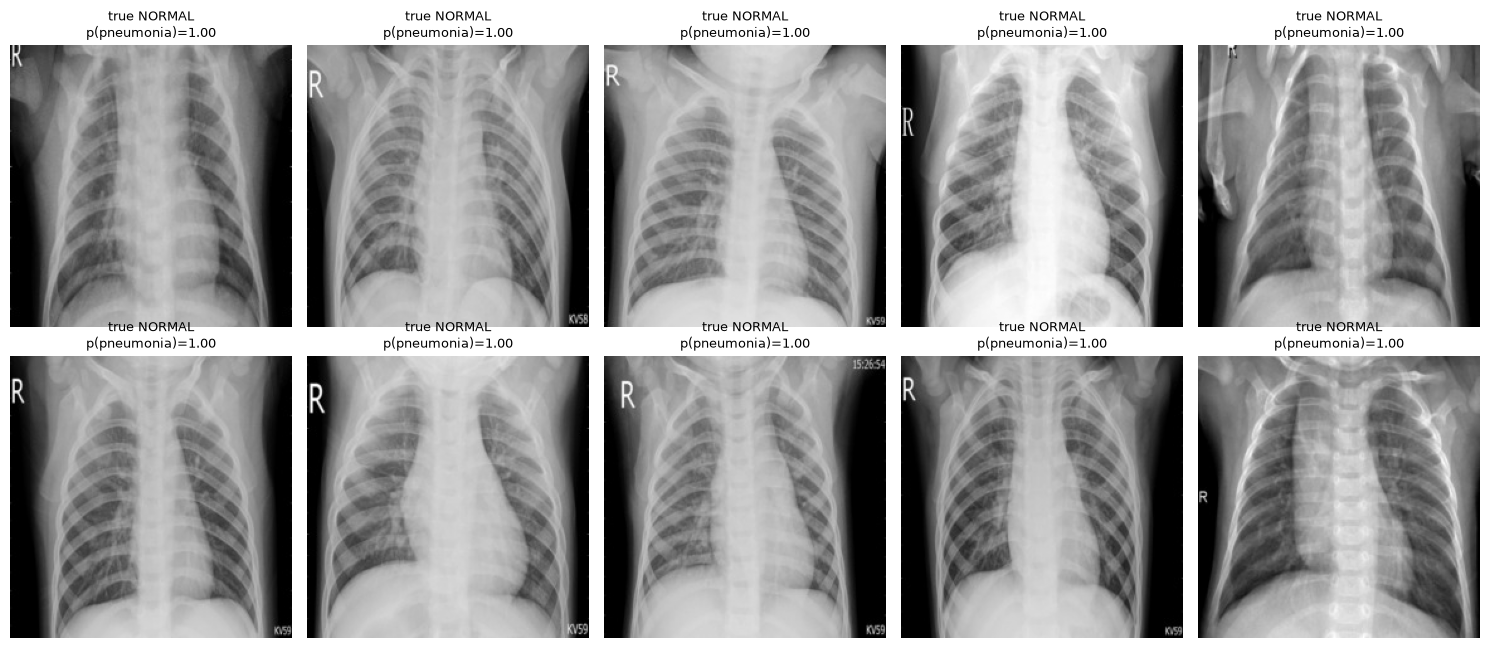

In [17]:
errors = test_df.assign(prob=final["test_prob"], pred=(final["test_prob"] >= threshold).astype(int))
errors = errors[errors.pred != errors.y].assign(conf=lambda d: (d.prob - 0.5).abs()).sort_values("conf", ascending=False)
print(f"{len(errors)} wrong out of {len(test_df)}:", errors.label.value_counts().to_dict())
fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for ax, (_, r) in zip(axes.ravel(), errors.head(10).iterrows()):
    ax.imshow(Image.open(r.path), cmap="gray")
    ax.set_title(f"true {r.label}\np(pneumonia)={r.prob:.2f}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("figures/errors.png", dpi=120)
plt.show()

**What the errors tell me**

All 109 mistakes are normal X-rays called pneumonia. The model never missed a pneumonia case on the test set (recall 1.00). For a screening tool this is the less dangerous direction, since a missed pneumonia can turn into sepsis while a false alarm means a doctor takes a second look. But 109 false alarms out of 234 healthy children is far too many to be useful.

The ROC-AUC of 0.969 says the model does rank most pneumonia images above most normal ones. The problem is where the cut-off sits. The threshold I chose on validation (0.49) is almost the default, because on validation the model barely made any of these mistakes. So the validation set could not show me this problem at all.

Looking at the images above, they are clean, healthy chests, and the model gives them a pneumonia probability of 1.00, so this is not borderline. Many of them have a "KV58" or "KV59" stamp in the bottom right corner and a big "R" marker in the top left, which looks different from the small R I saw in the average normal training image. I can't prove it from this alone, but it fits with what I saw in the data section: the model may have learned how the normal training images were taken (markers, framing, size) and not only what healthy lungs look like. When test normals were taken a bit differently, it treated them as "not normal".

What I would try next: crop or cover the corners where text markers sit before training, train with more normal images from other sources, and choose the threshold on a validation set that looks more like real new data. The retraining section below tries the last idea in a small way.

## 8. Saving the model

The final model is saved as `models/pneumonia_mobilenetv2.h5`. Next to it, `models/metadata.json` keeps the version number, threshold, test metrics and training history. The API reads both files, and the retraining job writes a new version of both.

In [18]:
metadata = {
    "version": 1,
    "name": "MobileNetV2 fine-tuned (E4)",
    "trained_on": f"{len(train_split)} train / {len(val_split)} validation images",
    "img_size": IMG_SIZE,
    "class_names": CLASS_NAMES,
    "threshold": round(threshold, 2),
    "test_metrics": test_metrics,
    "val_metrics": val_metrics,
    "experiments": table[table.split == "test"].drop(columns="split").to_dict(orient="records"),
    "history": {k: [float(v) for v in vals] for k, vals in histories[final_name].items()},
}
save_model(final["model"], metadata)
print(Path("models/pneumonia_mobilenetv2.h5").stat().st_size / 1e6, "MB")

24.699376 MB


## 9. Prediction function

`src/prediction.py` is what the API calls. It takes the raw bytes of an uploaded file, runs the same preprocessing (grayscale, EXIF rotation, resize, 3 channels) and returns the label with a probability. Here I load the saved file fresh, so this also checks that the .h5 file loads correctly, and try it on images from the new batch that the model has never seen.

In [19]:
from src.prediction import Predictor
predictor = Predictor()
sample = new_df.groupby("label").sample(4, random_state=1)
out = []
for _, r in sample.iterrows():
    p = predictor.predict_bytes(open(r.path, "rb").read())
    out.append({"file": Path(r.path).name, "true": r.label, "predicted": p["label"],
                "p_pneumonia": p["pneumonia_probability"], "ms": p["latency_ms"]})
pd.DataFrame(out)

,file,true,predicted,p_pneumonia,ms
0,NORMAL2-IM-0825-0001.jpg,NORMAL,NORMAL,4.000e-04,33.1
1,NORMAL2-IM-0872-0001.jpg,NORMAL,NORMAL,8.320e-02,33.4
2,IM-0222-0001.jpg,NORMAL,NORMAL,4.920e-02,31.3
3,NORMAL2-IM-1073-0001.jpg,NORMAL,NORMAL,4.150e-01,35.5
4,person1644_bacteria_4361.jpg,PNEUMONIA,PNEUMONIA,1.000e+00,31.8
5,person387_bacteria_1769.jpg,PNEUMONIA,PNEUMONIA,1.000e+00,30.9
6,person59_bacteria_283.jpg,PNEUMONIA,PNEUMONIA,1.000e+00,30.8
7,person1496_bacteria_3905.jpg,PNEUMONIA,PNEUMONIA,9.997e-01,30.8


In [20]:
# whole new batch, to see how the model does on images it has never seen
new_prob = np.array([predictor.predict_bytes(open(p, "rb").read())["pneumonia_probability"] for p in new_df.path])
before = evaluate(new_df.y, new_prob, predictor.threshold)
{k: round(v, 3) for k, v in before.items() if k not in ("confusion_matrix", "n", "threshold")}

{'loss': 0.121,
 'accuracy': 0.967,
 'precision': 0.938,
 'recall': 1.0,
 'specificity': 0.933,
 'f1': 0.968,
 'roc_auc': 0.998,
 'pr_auc': 0.998}

## 10. Retraining

In the app, new labelled images are uploaded, saved in a SQLite table, and a retraining job runs (`src/retrain.py`). Here is what the job does, step by step:

1. Takes the images in the database that have not been used for training yet.
2. Preprocesses them exactly like the training data (grayscale, 224x224).
3. Adds 300 random images per class from the original training set. Without them the model would only see the new images and could forget what it learned (catastrophic forgetting).
4. Loads the **saved model** as the starting point, so retraining continues from my trained model and does not start from zero.
5. Fine-tunes the last 40 layers for up to 4 epochs at learning rate 1e-5, with early stopping.
6. Evaluates the old and the new model on the test set. The new model only replaces the live one if its F1 did not drop by more than 0.01. The previous version is kept in `models/versions/`.

Below I run steps 2 to 5 by hand on half of the new batch, without saving, to check the idea works before putting it behind a button. The other half is used to check the result.

In [21]:
from src.retrain import replay_sample
from src.preprocessing import patient_split as split_by_patient

new_train, new_check = split_by_patient(new_df, val_frac=0.5, seed=7)
mix = pd.concat([new_train, replay_sample()], ignore_index=True)
mix_train, mix_val = split_by_patient(mix, val_frac=0.15)

retrained = unfreeze_top(load_model(), n_layers=40)   # the saved model is the pretrained starting point
compile_model(retrained, lr=1e-5)
retrained.fit(make_dataset(mix_train.path, mix_train.y, training=True, augment=True),
              validation_data=make_dataset(mix_val.path, mix_val.y), epochs=4,
              class_weight=class_weights(mix_train.y), callbacks=callbacks(patience=2), verbose=2)

check_ds = make_dataset(new_check.path, new_check.y)
old_model = load_model()
compare = pd.DataFrame({
    "saved model": evaluate(new_check.y, predict_proba(old_model, check_ds), threshold),
    "after retraining": evaluate(new_check.y, predict_proba(retrained, check_ds), threshold),
    "saved model (test set)": evaluate(test_df.y, predict_proba(old_model, test_ds), threshold),
    "after retraining (test set)": evaluate(test_df.y, predict_proba(retrained, test_ds), threshold),
}).drop(["confusion_matrix", "threshold"]).T
compare

Epoch 1/4


/Users/kalisabelyse/Documents/projects/ALU-Projects/pneumonia-xray-mlops/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


21/21 - 5s - 261ms/step - accuracy: 0.9713 - auc: 0.9931 - loss: 0.1116 - precision: 0.9789 - recall: 0.9643 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0474 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 1.0000e-05


Epoch 2/4


21/21 - 3s - 139ms/step - accuracy: 0.9683 - auc: 0.9940 - loss: 0.1094 - precision: 0.9758 - recall: 0.9613 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0446 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 1.0000e-05


Epoch 3/4


21/21 - 3s - 137ms/step - accuracy: 0.9743 - auc: 0.9973 - loss: 0.0888 - precision: 0.9790 - recall: 0.9702 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0618 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 1.0000e-05


Epoch 4/4


21/21 - 3s - 134ms/step - accuracy: 0.9819 - auc: 0.9961 - loss: 0.0835 - precision: 0.9909 - recall: 0.9732 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0369 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 1.0000e-05


,loss,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,n
saved model,0.159,0.943,0.885,1.0,0.9,0.939,1.0,1.0,53
after retraining,0.091,0.962,0.92,1.0,0.933,0.958,1.0,1.0,53
saved model (test set),0.638,0.825,0.782,1.0,0.534,0.877,0.969,0.979,624
after retraining (test set),0.418,0.861,0.82,0.995,0.637,0.899,0.971,0.98,624


**Did retraining help?**

Yes. On the half of the new batch that was not used for training, accuracy went from 94.3% to 96.2%. More interesting is the test set, which retraining never saw: specificity went from 0.534 to 0.637 and F1 from 0.877 to 0.899, while recall stayed at 0.995. Only about 60 new images and 4 short epochs moved the false alarm problem noticeably, which tells me the model was missing variety in its normal images more than it was missing capacity.

This is also why the retraining job compares old and new on the test set before swapping the model. If someone uploads badly labelled images, the new model could get worse, and the check stops it from going live.

## 11. Summary

The final model is MobileNetV2 fine-tuned on 4,374 X-rays (E4). On the 624 test images it gets accuracy 0.825, precision 0.782, recall 1.000, specificity 0.534, F1 0.877, ROC-AUC 0.969 and log loss 0.638.

Things that worked: transfer learning (better and four times faster than a CNN from scratch), splitting by patient, regularisation and fine-tuning with a small learning rate.

The weak point is false alarms on healthy children whose X-rays look different from the training images. The data exploration gave a likely reason (size, framing and side markers differ between the classes), the error analysis supports it, and retraining with a small batch of new images already improved it. In a real hospital I would want normal X-rays from more machines before trusting this model, and I would keep retraining it as new labelled images come in, which is what the deployed app is built to do.